# Serie III.3: rasgos y familias para pron?stico mensual

El objetivo es estimar el promedio mensual de cierres publicados a uno y tres meses, con incertidumbre. Comparo 19 configuraciones predefinidas, cuatro familias aprendidas (Ridge, SVR, Extra Trees y boosting), autorregresi?n directa regularizada y referencias de persistencia, deriva y suavizado exponencial. El [informe de Serie III](../docs/conclusiones-serie-III.md#3-pron?stico-a-uno-y-tres-meses-con-incertidumbre) re?ne la decisi?n gerencial.

La selecci?n usa febrero 2005?septiembre 2013; la calibraci?n enero 2014?septiembre 2018; la evaluaci?n desde enero 2019. Hay separaciones de tres meses para madurar etiquetas. Inspeccion? los datos de evaluaci?n en el EDA: **esta ampliaci?n es exploratoria, sin test nuevo ni certificaci?n contractual**. Registro la malla antes de calcular errores y no la ampl?o al ver la evaluaci?n. Conservo el experimento inicial del notebook 16.

**Propuesta de modelos:** Extra Trees a un mes y Ridge hist?rico a tres meses. La evaluaci?n es exploratoria y no un test ciego. El ?ltimo cierre conserva su condici?n de ganador de la selecci?n anterior y baseline. No existe un test a ciegas reservado en los datos actuales; esa comprobaci?n est? pendiente de datos no utilizados.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

raiz = Path.cwd()
if not (raiz / 'scripts').exists():
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from scripts.ampliar_pronostico_serie3 import ejecutar, CONJUNTOS
with threadpool_limits(limits=1):
    decision = ejecutar(raiz)
out = raiz / 'outputs/serie3_pronostico_ampliado'
print(json.dumps(decision, ensure_ascii=False, indent=2))

Selección a 1 meses calculada (19 candidatos).


Selección a 3 meses calculada (19 candidatos).


Calibración/evaluación a 1 meses calculadas.


Calibración/evaluación a 3 meses calculadas.


{
  "seleccionados": {
    "1": "ingenuo_cierre",
    "3": "ingenuo_cierre"
  },
  "n_configuraciones": 19,
  "n_rasgos": {
    "original": 3,
    "autorregresivos": 13,
    "historia": 17,
    "ohlc": 22,
    "completos": 24
  },
  "fuente_sha256": "944471f40adce9a236bc992e3824f8c07f8f87b0f1aa7a5e50c47c888dcd52d1",
  "filas_crudas": 6097,
  "filas_mes_incompleto": 15,
  "meses": 291,
  "meses_iniciales_sin_rasgos": 12,
  "test_nuevo": false,
  "continuidad_certificada": false,
  "tipo": "ampliación exploratoria con datos del enunciado; selección congelada por MAE",
  "sin_datos_externos": true
}


## Información disponible y conservación

Solo se usa `Sugar_data.csv`: OHLCV diario, sin fundamentales ni fechas históricas de publicación FAOSTAT. No se incorpora producción anual como si se conociera en tiempo real. Los conjuntos contienen 3 rasgos originales; 13 autorregresivos; 17 de historia/tendencia, volatilidad y calendario; 22 al añadir rango, cuerpo de vela, volatilidad diaria, riesgo bajista y cambio de cinco sesiones; y 24 al añadir volumen relativo a tres/doce meses. Los conjuntos autorregresivo e histórico son alternativas, no 13+17 variables sumadas.

Los rangos/cuerpos utilizan únicamente días con OHLC coherente. Los volúmenes cero se conservan pero no se tratan como actividad confirmada al calcular volumen medio. La volatilidad diaria usa retornos originales con máscaras explícitas de calidad/frontera; no une fechas tras filtrar. La frontera del mes completo es conocida al cierre, sin esperar datos del siguiente mes. Los rasgos de cierre y cambios largos siguen expuestos al enlace no certificado.

Se conservan 6,097 días: 6,082 forman 291 meses completos y 15 de junio parcial quedan separados. Los primeros doce meses sin rasgos completos permanecen en archivo, con motivo y como antecedentes. No hay imputación de datos ni exclusiones automáticas de meses por rareza. Los modelos directos comparten el inicio de ajuste en el mes 13; por eso `ridge_original` reproduce la especificación de tres rasgos con esa historia común, sin sobrescribir el ajuste anterior.

In [2]:
m = pd.read_csv(out/'mensual_y_rasgos.csv')
d = pd.read_csv(out/'dias_y_uso_rasgos.csv')
p = pd.read_csv(out/'predicciones_historicas.csv')
tabla = pd.read_csv(out/'metricas.csv')
representantes = pd.read_csv(out/'representantes_familias.csv')
display(pd.DataFrame([{'conjunto':k,'n_rasgos':len(v),'rasgos':', '.join(v)} for k,v in CONJUNTOS.items()]))
display(pd.DataFrame([{'uso':c,'incluidos':int(d[c].sum()),'fuera_de_ese_uso':int((~d[c]).sum())} for c in ['uso_mes_completo','uso_ohlc','uso_volumen','uso_retorno_volatilidad']]))
display(representantes)
print('Cada observación conserva sus columnas originales y motivos en dias_y_uso_rasgos.csv.')

,conjunto,n_rasgos,rasgos
0,original,3,"log_cierre_sobre_media, cambio_media_1m, cambi..."
1,autorregresivos,13,"log_cierre_sobre_media, cambio_media_1m, retor..."
2,historia,17,"log_cierre_sobre_media, cambio_media_1m, cambi..."
3,ohlc,22,"log_cierre_sobre_media, cambio_media_1m, cambi..."
4,completos,24,"log_cierre_sobre_media, cambio_media_1m, cambi..."


,uso,incluidos,fuera_de_ese_uso
0,uso_mes_completo,6082,15
1,uso_ohlc,6071,26
2,uso_volumen,5990,107
3,uso_retorno_volatilidad,5734,363


,horizonte,familia,metodo,MAE_seleccion
0,1,referencia,ingenuo_cierre,0.896414
1,1,deriva,deriva,1.239250
2,1,suavizado,suavizado,1.222318
3,1,ridge_original,ridge_original,0.913407
4,1,ridge_autorregresivos,ridge_autorregresivos_100,0.908332
5,1,ridge_historia,ridge_historia_100,0.914851
6,1,ridge_ohlc,ridge_ohlc_100,0.929184
7,1,ridge_completos,ridge_completos_100,0.942008
8,1,svr,svr_0.1,0.974247
9,1,extra_trees,extra_trees_10,0.913697


Cada observación conserva sus columnas originales y motivos en dias_y_uso_rasgos.csv.


## Comparación temporal

Cada modelo directo predice `log(promedio_futuro/cierre_origen)` y transforma el resultado a centavos USD/libra. Solo entran etiquetas con `j+h <= origen`; escalado y ajuste se repiten dentro de cada historia creciente. SVR usa kernel radial; Extra Trees utiliza 100 árboles, hojas mínimas 5/10 y 80 % de variables; boosting usa 80 iteraciones, cinco hojas y sin parada temprana aleatoria. Ridge prueba penalizaciones 100/10. El suavizado optimiza su coeficiente con errores pasados de un paso, sobre log de promedios mensuales; deriva prolonga la pendiente logarítmica histórica.

Se elige por menor complejidad en el orden de la malla dentro de 2 % del MAE mínimo de selección. La malla tiene 19 configuraciones, no 19 familias independientes. Después se congelan el elegido y el representante con menor MAE de selección de cada familia/conjunto; solo esos representantes pasan a calibración/evaluación. La decisión no se cambia mirando el ranking posterior. Las ablaciones de variables se contrastan en Ridge con igual muestra; no atribuyen causalidad ni demuestran el aporte de esas variables en todos los algoritmos.

Horizonte 1: selección (104 orígenes por configuración)


,metodo,n,MAE,WAPE_pct
53,ingenuo_cierre,104,0.896414,5.221439
56,ridge_autorregresivos_100,104,0.908332,5.290858
63,ridge_original,104,0.913407,5.320421
51,extra_trees_10,104,0.913697,5.322112
60,ridge_historia_100,104,0.914851,5.328831
62,ridge_ohlc_100,104,0.929184,5.412317
52,extra_trees_5,104,0.931540,5.426043
58,ridge_completos_100,104,0.942008,5.487018
55,ridge_autorregresivos_10,104,0.942810,5.491690
59,ridge_historia_10,104,0.957406,5.576709


Evaluación exploratoria de representantes


,metodo,n,MAE,WAPE_pct
26,extra_trees_10,64,0.651709,3.704038
24,boosting_10,64,0.658806,3.744374
30,ridge_completos_100,64,0.673533,3.828074
31,ridge_historia_100,64,0.678466,3.856113
32,ridge_ohlc_100,64,0.682392,3.878426
27,ingenuo_cierre,64,0.694164,3.945331
33,ridge_original,64,0.702018,3.989972
29,ridge_autorregresivos_100,64,0.716934,4.074746
35,svr_0.1,64,0.755848,4.295920
25,deriva,64,0.849450,4.827914


Horizonte 3: selección (104 orígenes por configuración)


,metodo,n,MAE,WAPE_pct
72,ingenuo_cierre,104,2.599275,14.998836
70,extra_trees_10,104,2.638683,15.226231
71,extra_trees_5,104,2.681764,15.474828
84,svr_0.1,104,2.684554,15.490924
73,ingenuo_media,104,2.716499,15.675262
83,suavizado,104,2.716754,15.676734
75,ridge_autorregresivos_100,104,2.717009,15.678206
82,ridge_original,104,2.724520,15.721547
69,deriva,104,2.802832,16.173436
79,ridge_historia_100,104,2.805679,16.189865


Evaluación exploratoria de representantes


,metodo,n,MAE,WAPE_pct
43,ridge_historia_100,62,1.630385,9.184025
44,ridge_ohlc_100,62,1.631589,9.190803
42,ridge_completos_100,62,1.635879,9.214972
45,ridge_original,62,1.643328,9.256930
39,ingenuo_cierre,62,1.652727,9.309875
47,svr_0.1,62,1.652929,9.311012
41,ridge_autorregresivos_100,62,1.667542,9.393330
37,deriva,62,1.704168,9.599644
46,suavizado,62,1.709508,9.629723
40,ingenuo_media,62,1.709530,9.629849


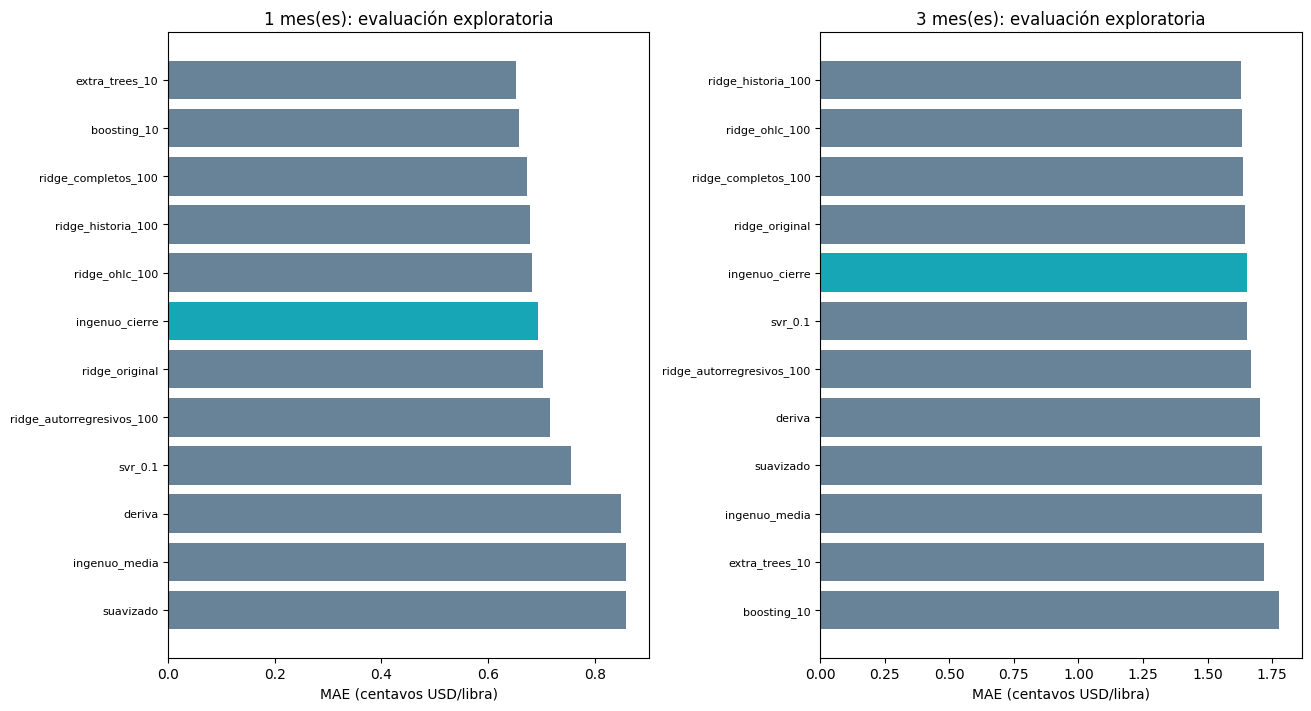

In [3]:
for h in [1,3]:
    print(f'Horizonte {h}: selección (104 orígenes por configuración)')
    display(tabla[(tabla.horizonte==h)&(tabla.fase=='seleccion')].sort_values('MAE')[['metodo','n','MAE','WAPE_pct']])
    print('Evaluación exploratoria de representantes')
    display(tabla[(tabla.horizonte==h)&(tabla.fase=='evaluacion')].sort_values('MAE')[['metodo','n','MAE','WAPE_pct']])
fig, axes = plt.subplots(1,2,figsize=(13,7),constrained_layout=True)
for ax,h in zip(axes,[1,3]):
    t=tabla[(tabla.horizonte==h)&(tabla.fase=='evaluacion')].sort_values('MAE',ascending=False)
    ax.barh(t.metodo,t.MAE,color=['#16a6b6' if n=='ingenuo_cierre' else '#688297' for n in t.metodo])
    ax.set(title=f'{h} mes(es): evaluación exploratoria',xlabel='MAE (centavos USD/libra)')
    ax.tick_params(axis='y',labelsize=8)
fig.savefig(out/'comparacion_modelos.png',dpi=150)
plt.show()

## Estabilidad y alcance de la mejora

El último cierre obtiene el menor MAE de selección en ambos horizontes. En la evaluación posterior, Extra Trees mejora a un mes y empeora a tres; a tres meses la mayor mejora agregada de los representantes es pequeña y corresponde a Ridge histórico. Son candidatos de seguimiento, no ganadores elegidos con un test independiente.

El desglose por año y la sensibilidad sin marcas directas en los meses de emisión/objetivo evitan resumir toda la evidencia en un único porcentaje. La sensibilidad no excluye retrospectivamente todos los antecedentes de entrenamiento ni certifica continuidad. Los años parciales y los errores solapados no son réplicas independientes. No se aplica una prueba de significancia iid ni se promete ganancia de una estrategia comercial.

1 extra_trees_10 reducción MAE (%) 6.1159361870113615
3 ridge_historia_100 reducción MAE (%) 1.3517821373665306
2024 contiene cinco objetivos, hasta mayo. Mayor que cero favorece al candidato.


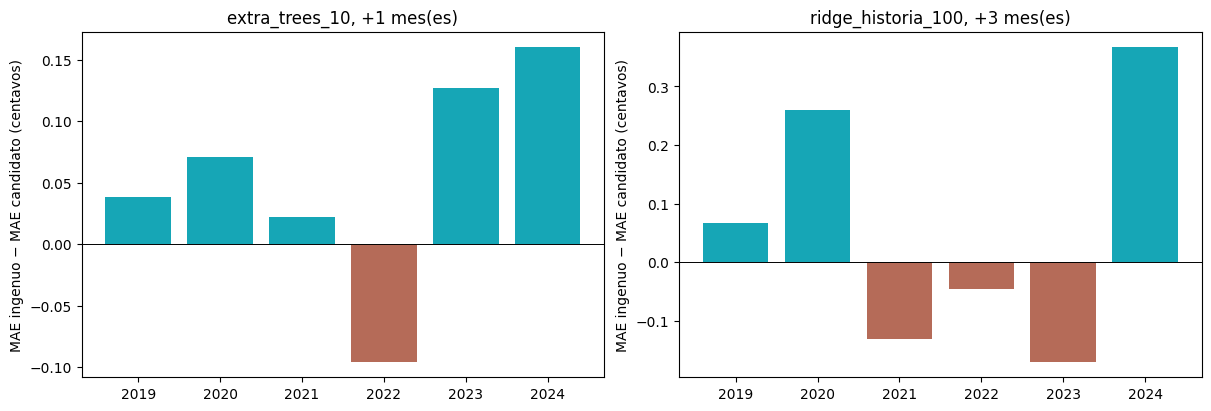

,horizonte,metodo,n,MAE,RMSE,WAPE_pct,sesgo
0,1,boosting_10,47,0.530069,0.689867,3.075271,-0.040471
1,1,deriva,47,0.694498,0.886377,4.029228,-0.163691
2,1,extra_trees_10,47,0.547856,0.713609,3.178462,-0.083189
3,1,ingenuo_cierre,47,0.589849,0.773256,3.422092,-0.109053
4,1,ingenuo_media,47,0.710112,0.899951,4.119816,-0.241297
5,1,ridge_autorregresivos_100,47,0.604757,0.797492,3.508582,-0.094044
6,1,ridge_completos_100,47,0.560513,0.731111,3.251897,-0.114102
7,1,ridge_historia_100,47,0.564633,0.732380,3.275799,-0.078407
8,1,ridge_ohlc_100,47,0.569267,0.736832,3.302686,-0.112796
9,1,ridge_original,47,0.599579,0.786282,3.478541,-0.089141


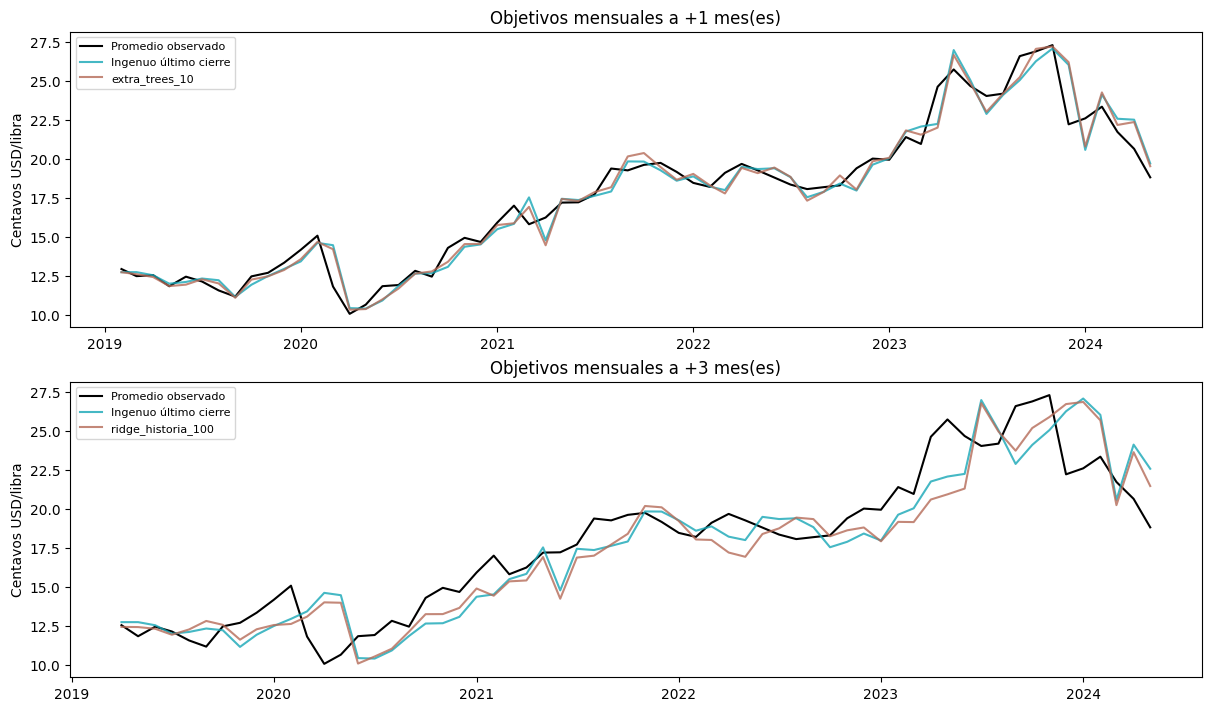

In [4]:
test = p[p.fase=='evaluacion'].copy()
test['ano']=test.objetivo.str[:4].astype(int)
fig, axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for ax,h,nombre in zip(axes,[1,3],['extra_trees_10','ridge_historia_100']):
    a=test[(test.horizonte==h)&(test.metodo==nombre)].set_index('origen')
    b=test[(test.horizonte==h)&(test.metodo=='ingenuo_cierre')].set_index('origen')
    a['ventaja']=abs(b.prediccion-b.observado)-abs(a.prediccion-a.observado)
    por_ano=a.groupby('ano').ventaja.mean()
    ax.bar(por_ano.index.astype(str),por_ano,color=['#16a6b6' if v>=0 else '#b56b58' for v in por_ano])
    ax.axhline(0,color='black',linewidth=.7)
    ax.set(title=f'{nombre}, +{h} mes(es)',ylabel='MAE ingenuo − MAE candidato (centavos)')
    print(h,nombre,'reducción MAE (%)',100*(1-abs(a.prediccion-a.observado).mean()/abs(b.prediccion-b.observado).mean()))
print('2024 contiene cinco objetivos, hasta mayo. Mayor que cero favorece al candidato.')
fig.savefig(out/'estabilidad_por_ano.png',dpi=150)
plt.show()
display(pd.read_csv(out/'sensibilidad_calidad.csv'))
fig, axes=plt.subplots(2,1,figsize=(12,7),constrained_layout=True)
for ax,h,nombre in zip(axes,[1,3],['extra_trees_10','ridge_historia_100']):
    a=test[(test.horizonte==h)&(test.metodo==nombre)].sort_values('objetivo')
    b=test[(test.horizonte==h)&(test.metodo=='ingenuo_cierre')].sort_values('objetivo')
    fechas=pd.to_datetime(a.objetivo)
    ax.plot(fechas,a.observado,label='Promedio observado',color='black')
    ax.plot(fechas,b.prediccion,label='Ingenuo último cierre',color='#16a6b6',alpha=.8)
    ax.plot(fechas,a.prediccion,label=nombre,color='#b56b58',alpha=.8)
    ax.set(title=f'Objetivos mensuales a +{h} mes(es)',ylabel='Centavos USD/libra')
    ax.legend(fontsize=8)
fig.savefig(out/'trayectorias_pronosticos.png',dpi=150)
plt.show()

## Incertidumbre y utilidad gerencial

Las bandas nominales 80/95 % se calibran con los 57 errores absolutos logarítmicos de 2014–2018 de cada representante, por horizonte. Se congelan antes de la evaluación; se comprueban cobertura, amplitud y Winkler. No ofrecen garantía probabilística futura. Los pronósticos finales usan mayo de 2024 para junio/agosto de 2024; son históricos.

**Modelos propuestos:** Extra Trees a un mes y Ridge histórico a tres, con bandas y comparación con el último cierre. Su elección es exploratoria tras observar la evaluación: la mejora de Ridge es pequeña y la de Extra Trees depende del periodo. La elección temporal anterior del ingenuo se conserva sin reescribirla. La confirmación independiente permanece pendiente: no existe un bloque reservado a ciegas dentro de los datos actuales. La información OHLCV permite un contraste más amplio sin salir del enunciado; no garantiza dominar al ingenuo ni explica causas económicas. No se cuantifica ahorro, cobertura rentable o beneficio de Santa Ana.

Para una confirmación comercial faltan contratos/ajustes certificados, diferencial físico y exposición del ingenio. Un periodo verdaderamente no utilizado permitiría contrastar al candidato ya fijado. Incorporar fundamentales o FAOSTAT requeriría fechas de publicación y revisiones para evitar anticipación; no se realiza esa ampliación de datos en este ejercicio.

In [5]:
propuesta=json.loads((out/'decision_propuesta.json').read_text(encoding='utf-8'))
print(json.dumps(propuesta,ensure_ascii=False,indent=2))
display(pd.read_csv(out/'pronosticos_propuestos.csv'))
display(pd.read_csv(out/'intervalos_propuestos.csv'))
print('Artefacto con dos modelos entrenados: outputs/serie3_pronostico_ampliado/modelos_propuestos.joblib')
print('Pruebas: python -m pytest tests/unitarias/test_pronostico_ampliado_serie3.py tests/integracion/test_pronostico_ampliado_serie3_resultados.py -q')

{
  "propuestos": {
    "1": "extra_trees_10",
    "3": "ridge_historia_100"
  },
  "ganadores_seleccion_previa": {
    "1": "ingenuo_cierre",
    "3": "ingenuo_cierre"
  },
  "criterio": "propuesta exploratoria por mejora posterior y horizonte; evaluación ya inspeccionada",
  "evaluacion_reutilizada": true,
  "test_ciego": {
    "reservado_en_datos_actuales": false,
    "ejecutado": false,
    "estado": "pendiente; requiere datos no utilizados"
  },
  "uso": "prototipo para planificación y escenarios; sin validación comercial",
  "origen_historico": "2024-05",
  "fuente_sha256": "944471f40adce9a236bc992e3824f8c07f8f87b0f1aa7a5e50c47c888dcd52d1",
  "continuidad_certificada": false
}


,origen,objetivo,horizonte,metodo,ganador_seleccion_previa,prediccion,inferior_80,superior_80,inferior_95,superior_95,propuesto
0,2024-05,2024-06,1,extra_trees_10,False,18.245385,16.975703,19.610031,15.905257,20.929813,True
1,2024-05,2024-08,3,ridge_historia_100,False,18.850328,16.010427,22.193966,14.447716,24.594536,True


,horizonte,metodo,ganador_seleccion_previa,cobertura_nominal,q_log,orden,n_calibracion,n,aciertos,cobertura_real_pct,amplitud_media,Winkler_medio,propuesto
0,1,extra_trees_10,False,0.80,0.072129,47,57,64,56,87.500000,2.534875,3.428384,True
1,1,extra_trees_10,False,0.95,0.137262,56,57,64,62,96.875000,4.834867,5.586021,True
2,3,ridge_historia_100,False,0.80,0.163290,47,57,62,53,85.483871,5.679689,6.635646,True
3,3,ridge_historia_100,False,0.95,0.265994,56,57,62,60,96.774194,9.320032,9.803044,True


Artefacto con dos modelos entrenados: outputs/serie3_pronostico_ampliado/modelos_propuestos.joblib
Pruebas: python -m pytest tests/unitarias/test_pronostico_ampliado_serie3.py tests/integracion/test_pronostico_ampliado_serie3_resultados.py -q


## Evidencia reproducible

[Módulo del experimento](../scripts/ampliar_pronostico_serie3.py), [pruebas temporales](../tests/unitarias/test_pronostico_ampliado_serie3.py) y [reconstrucción independiente](../tests/integracion/test_pronostico_ampliado_serie3_resultados.py). Resultados locales en `outputs/serie3_pronostico_ampliado/`, fuera de Git. Incluyen diseño previo, conjuntos/configuraciones, todas las predicciones de selección, representantes congelados, ajustes/muestras, métricas por fase/año/calidad, bandas, pronósticos, pipelines y conservación de observaciones con motivos.

Las pruebas reconstruyen rasgos desde el crudo y Ridge por solución matricial, perturban y truncan el futuro para comprobar disponibilidad, recalculan elección/errores/bandas y contrastan los pipelines finales. No certifican todos los movimientos del mercado ni precisión futura.

`modelos_propuestos.joblib` contiene los pipelines Extra Trees +1 y Ridge historia +3, con columnas, configuración y bandas. `decision_propuesta.json` distingue propuesta posterior y ganador de selección previo; declara que el test ciego no está reservado ni ejecutado. `pronosticos_propuestos.csv` e `intervalos_propuestos.csv` concentran los resultados entregados.